## Implementation of Linear regression using python

In [8]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt


## Load the dataset

In [9]:
DF1 = pd.read_csv("weight-height - weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [20]:
col=["Height","Weight"]
S1=MinMaxScaler()
DF1[col]=S1.fit_transform(DF1[col])
DF1.head()

,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [11]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

In [15]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
Y.shape

(10000, 1)

## Split the data into training and test set

In [21]:
 X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [22]:
# Create a linear regression model

model=LinearRegression()



Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [34]:
## Training  Linear regressions model 

In [23]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [24]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


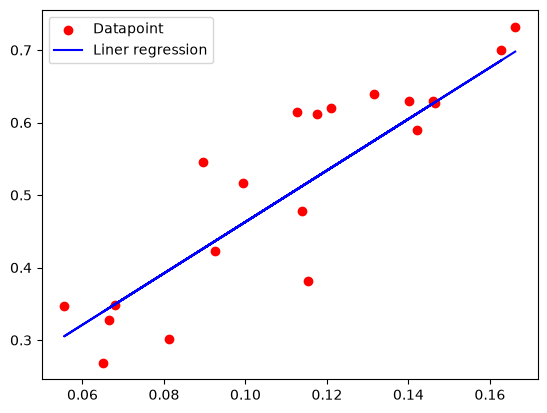

In [25]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()


In [38]:
## Load the Height and weight  to indipendent and dependent variable 

In [30]:
df2=pd.read_csv("weight-height - weight-height.csv")
X = df2['Height'].values.reshape(-1,1)
X.shape
Y = df2['Weight'].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [31]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)


[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [33]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [34]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=1000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[]
print(X.shape)
m=X.T
print(m.shape)

(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [35]:
for i in range(iterations):
    y_pred=np.dot(X,theta)
    mse=mean_squared_error(Y,y_pred)
    mseh.append(mse)
    print(f"Iteration {i+1} : MSE={mse}")
    gradient=np.dot(X.T,(y_pred-Y))/len(Y)
    theta-= learningrate * gradient

Iteration 1 : MSE=1.0
Iteration 2 : MSE=0.985809419277575
Iteration 3 : MSE=0.9719012311115264
Iteration 4 : MSE=0.9582698158899818
Iteration 5 : MSE=0.9449096658313463
Iteration 6 : MSE=0.9318153827588774
Iteration 7 : MSE=0.9189816759195508
Iteration 8 : MSE=0.9064033598463267
Iteration 9 : MSE=0.8940753522629599
Iteration 10 : MSE=0.8819926720305018
Iteration 11 : MSE=0.87015043713467
Iteration 12 : MSE=0.8585438627132649
Iteration 13 : MSE=0.847168259122846
Iteration 14 : MSE=0.8360190300438766
Iteration 15 : MSE=0.8250916706235781
Iteration 16 : MSE=0.8143817656557442
Iteration 17 : MSE=0.8038849877967698
Iteration 18 : MSE=0.7935970958171891
Iteration 19 : MSE=0.7835139328880019
Iteration 20 : MSE=0.7736314249011057
Iteration 21 : MSE=0.7639455788231487
Iteration 22 : MSE=0.7544524810821431
Iteration 23 : MSE=0.7451482959861835
Iteration 24 : MSE=0.7360292641736333
Iteration 25 : MSE=0.727091701094153
Iteration 26 : MSE=0.7183319955199544
Iteration 27 : MSE=0.7097466080866824
Ite

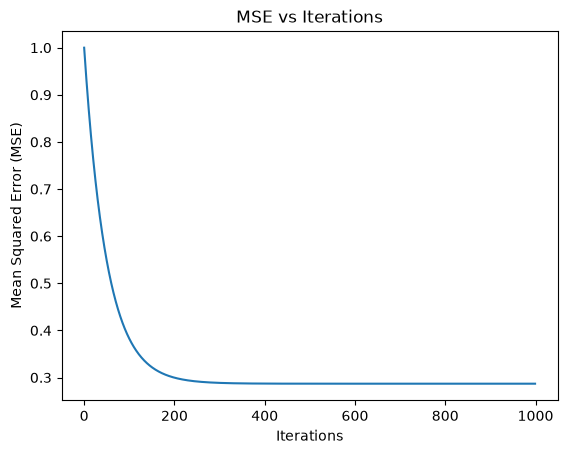

In [36]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

In [37]:
print(theta)

[1.30148203e-15 8.44412778e-01]


## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("Food_Delivery_Times - Food_Delivery_Times.csv")

df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [3]:
X = df[
    [
        "Distance_km",
        "Preparation_Time_min",
        "Traffic_Level",
        "Weather"
    ]
]

Y = df["Delivery_Time_min"]

X.head()

,Distance_km,Preparation_Time_min,Traffic_Level,Weather
0,7.93,12,Low,Windy
1,16.42,20,Medium,Clear
2,9.52,28,Low,Foggy
3,7.44,5,Medium,Rainy
4,19.03,16,Low,Clear


In [4]:
X = pd.get_dummies(
    X,
    columns=["Traffic_Level", "Weather"],
    drop_first=True,
    dtype=int
)

X.head()

,Distance_km,Preparation_Time_min,Traffic_Level_Low,Traffic_Level_Medium,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
0,7.93,12,1,0,0,0,0,1
1,16.42,20,0,1,0,0,0,0
2,9.52,28,1,0,1,0,0,0
3,7.44,5,0,1,0,1,0,0
4,19.03,16,1,0,0,0,0,0


In [5]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

In [6]:
model = LinearRegression()

model.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 3. , 0.99,-10.45,..., 4.45, 9.31, 1.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Distance_km','Preparation_Time_min','Traffic_Level_Low',..., 'Weather_Rainy','Weather_Snowy','Weather_Windy']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,13.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [7]:
Y_pred = model.predict(X_test)

print("Predicted Delivery Times:")
print(Y_pred[:10])

Predicted Delivery Times:
[34.59395202 69.36780005 43.747188   42.09533319 77.85132521 34.16249417
 68.69563768 28.68790497 37.33400224 78.03330836]


In [8]:

mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("Mean Absolute Error:", mae)
print("R-squared Score:", r2)

Mean Squared Error: 81.21777643790075
Root Mean Squared Error: 9.012090569779065
Mean Absolute Error: 6.1741947711167855
R-squared Score: 0.8188021226569402


In [9]:
import pandas as pd
import numpy as np

results = pd.DataFrame({
    "Actual Delivery Time": np.asarray(Y_test).ravel(),
    "Predicted Delivery Time": np.asarray(Y_pred).ravel()
})

print(results.head(10))

   Actual Delivery Time  Predicted Delivery Time
0                    32                34.593952
1                    68                69.367800
2                    39                43.747188
3                    44                42.095333
4                    85                77.851325
5                    31                34.162494
6                    77                68.695638
7                    33                28.687905
8                    90                37.334002
9                    91                78.033308


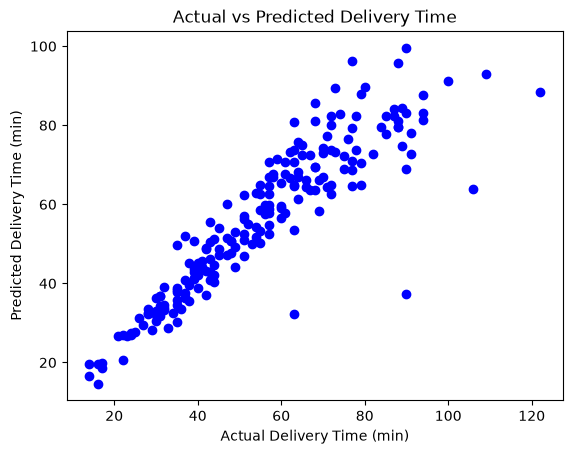

In [10]:
plt.scatter(Y_test, Y_pred, color="blue")

plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("Actual vs Predicted Delivery Time")

plt.show()

In [11]:
print("Regression Coefficients:")
print(model.coef_)

print("Intercept:")
print(model.intercept_)

Regression Coefficients:
[  2.9950145    0.98541388 -10.45084827  -4.93259961   6.10558262
   4.44693374   9.31249458   1.09834694]
Intercept:
13.404601307526967
